<a href="https://colab.research.google.com/github/MoeTahech/real-fake-face-detection-thesis/blob/main/notebooks/12_degradation_robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 14 — Phase 12: Robustness to Real-World Degradations

**The question:** In the lab our detectors score 0.99. But a real fake image gets screenshotted, compressed by WhatsApp, resized by Instagram, or blurred by a bad camera. **Does the score survive?**

**Exam analogy:** until now the exam papers were clean, crisp printouts. This is the same exam photocopied badly: faded, blurry, shrunk. Does the student still pass?

**How it differs from Phase 5.** Phase 5 (FGSM/PGD) attacked the models with *deliberately crafted* noise. Here the damage is *ordinary*, what happens to pictures in daily life. It complements Phase 5 with a more realistic threat.

**What the notebook does (no retraining)**
It re-scores your existing P2 / P6 / P9 models (all 3 seeds from notebook 11) on the evaluation sets after applying degradations at several strengths:

| Family | Strengths tested | Real-life example |
|---|---|---|
| JPEG compression | quality 90, 70, 50, 30 | saving or sharing a photo |
| Gaussian blur | sigma 0.5, 1, 2, 3 | out-of-focus or smoothed image |
| Downscale then upscale | x0.75, x0.5, x0.25 | low-resolution upload |
| Gaussian noise | sigma 2, 5, 10 (out of 255) | grainy or low-light camera |
| "Social media" combo | shrink to half, then JPEG 70 | a typical repost |

The same images are used in every condition, so any change is caused by the degradation alone.

**Read the results carefully.** A robustness test only makes sense where the model works on clean images. P2 on face-swap (AUC about 0.5) is already failing, so "how much does it drop?" means nothing. The notebook marks such cases (clean AUC below 0.75) as **not meaningful** and focuses on the others: all models on StyleGAN, P6 and P9 on face-swap, P9 on diffusion.

**Requirements:** notebook 11's Drive folder (`seed_runs/` with `p2/p6/p9_seed*.pth` and `diffusion_split.json`).

**Estimated time (T4, not measured):** about 15-20 min setup (dataset downloads), 15-25 min scoring, 2-3 min bootstrap. Total about 35-50 min. It saves progress to Drive, so it resumes after a disconnect.

### Step 1 — GPU and Drive

In [ ]:
!nvidia-smi

Thu Oct 15 11:08:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
CHECKPOINT_DIR = '/content/drive/MyDrive/thesis_checkpoints'
SEED_DIR = f'{CHECKPOINT_DIR}/seed_runs'
DEG_DIR  = f'{CHECKPOINT_DIR}/degradation_check'
os.makedirs(DEG_DIR, exist_ok=True)
for need in ['p2_seed0.pth', 'p6_seed0.pth', 'p9_seed0.pth', 'diffusion_split.json']:
    print(('OK      ' if os.path.exists(f'{SEED_DIR}/{need}') else 'MISSING ') + need)

Mounted at /content/drive
OK      p2_seed0.pth
OK      p6_seed0.pth
OK      p9_seed0.pth
OK      diffusion_split.json


### Step 2 — Settings
- `EVAL_N`: images per class per domain (`None` = all). 1,500 keeps it fast; the diffusion set only has 1,015 per class anyway.
- `MODEL_SEEDS`: which seeds of P2/P6/P9 to test (scoring is cheap, so all three).
- `MEANINGFUL_AUC`: a model/domain pair counts as meaningful for robustness only if its clean AUC is at least this.

In [ ]:
EVAL_N = 1500
MODEL_SEEDS = [0, 1, 2]
MEANINGFUL_AUC = 0.75
N_BOOT = 300

### Step 3 — Kaggle access and datasets

In [ ]:
import os

os.environ["KAGGLE_API_TOKEN"] = "YOUR_KAGGLE_TOKEN_API_HERE"

In [ ]:
!pip install -q kaggle
!kaggle datasets download -d xhlulu/140k-real-and-fake-faces
!unzip -q 140k-real-and-fake-faces.zip -d data_raw
!kaggle datasets download -d manjilkarki/deepfake-and-real-images
!unzip -q deepfake-and-real-images.zip -d data_raw_2
!kaggle datasets download -d bwandowando/faces-dataset-using-stable-diffusion-v14
!unzip -q faces-dataset-using-stable-diffusion-v14.zip -d data_diffusion
print("All three datasets downloaded.")

Dataset URL: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces
License(s): other
100% 3.75G/3.75G [00:36<00:00, 112MB/s]

Dataset URL: https://www.kaggle.com/datasets/manjilkarki/deepfake-and-real-images
License(s): unknown
100% 1.68G/1.68G [00:19<00:00, 90.7MB/s]

Dataset URL: https://www.kaggle.com/datasets/bwandowando/faces-dataset-using-stable-diffusion-v14
License(s): CC0-1.0
100% 1.10G/1.10G [00:15<00:00, 78.1MB/s]

All three datasets downloaded.


### Step 4 — Rebuild the three evaluation sets (identical to notebooks 11-13)

In [ ]:
import os, random, json
import numpy as np

def find_real_fake_folders(root):
    out = []
    for dp, dn, _ in os.walk(root):
        low = [d.lower() for d in dn]
        if "real" in low and "fake" in low: out.append(dp)
    return out
def find_split(root, kw):
    c = find_real_fake_folders(root); m = [x for x in c if kw in x.lower()]
    if not m: raise FileNotFoundError(f"No folder containing '{kw}' under {root}. Found: {c}")
    return m[0]
def find_class_dir(split_root, cls):
    for d in os.listdir(split_root):
        if d.lower() == cls: return os.path.join(split_root, d)
    raise FileNotFoundError(f"No '{cls}' folder in {split_root}")
def link(src, dst):
    if not os.path.exists(dst): os.symlink(os.path.abspath(src), dst)

styleGAN_test = find_split("data_raw", "test")
faceswap_test = find_split("data_raw_2", "test")
SPLIT_FILE = f"{SEED_DIR}/diffusion_split.json"
if not os.path.exists(SPLIT_FILE): raise FileNotFoundError("diffusion_split.json not found. Run notebook 11 first.")
sp = json.load(open(SPLIT_FILE))
diffusion_heldout_images = [os.path.join("data_diffusion", p) for p in sp["heldout"]]

def build_eval_subset(source_root, dst_root, n_per_class, seed=99):
    rng = random.Random(seed)
    for cls in ["real", "fake"]:
        os.makedirs(f"{dst_root}/{cls}", exist_ok=True)
        cd = find_class_dir(source_root, cls); files = sorted(os.listdir(cd)); rng.shuffle(files)
        for f in files[:n_per_class]: link(os.path.join(cd, f), f"{dst_root}/{cls}/{f}")
def build_eval_diffusion(dst_root, fake_paths, real_dir, seed=7):
    rng = random.Random(seed)
    os.makedirs(f"{dst_root}/fake", exist_ok=True); os.makedirs(f"{dst_root}/real", exist_ok=True)
    reals = sorted(os.listdir(real_dir)); rng.shuffle(reals); reals = reals[:len(fake_paths)]
    for i, p in enumerate(sorted(fake_paths)): link(p, f"{dst_root}/fake/{i}_{os.path.basename(p)}")
    for i, f in enumerate(reals):              link(os.path.join(real_dir, f), f"{dst_root}/real/{i}_{f}")

build_eval_subset(styleGAN_test, "eval_stylegan", 5000)
build_eval_subset(faceswap_test, "eval_faceswap", 5000)
build_eval_diffusion("eval_diffusion", diffusion_heldout_images, find_class_dir(styleGAN_test, "real"))
EVAL_SETS = {"stylegan": "eval_stylegan", "faceswap": "eval_faceswap", "diffusion": "eval_diffusion"}
for k, v in EVAL_SETS.items(): print(k, {c: len(os.listdir(f"{v}/{c}")) for c in ["real", "fake"]})

stylegan {'real': 5000, 'fake': 5000}
faceswap {'real': 5000, 'fake': 5000}
diffusion {'real': 1015, 'fake': 1015}


## Step 5 — Define the degradations

Each degradation is applied to the image **before** the normal preprocessing (resize to 224, normalize). Noise is seeded from the file name, so the same image always gets the same noise.

In [ ]:
import io, zlib
from PIL import Image, ImageFilter

def d_jpeg(im, q):
    buf = io.BytesIO(); im.save(buf, format="JPEG", quality=int(q)); buf.seek(0); return Image.open(buf).convert("RGB")
def d_blur(im, s): return im.filter(ImageFilter.GaussianBlur(radius=float(s)))
def d_down(im, f):
    w, h = im.size; small = im.resize((max(8, round(w * f)), max(8, round(h * f))), Image.BICUBIC)
    return small.resize((w, h), Image.BICUBIC)
def d_noise(im, sigma, path):
    rng = np.random.default_rng(zlib.crc32(path.encode()))
    a = np.asarray(im, dtype=np.float32) + rng.normal(0, float(sigma), (im.size[1], im.size[0], 3))
    return Image.fromarray(np.clip(a, 0, 255).astype("uint8"))

OPS = {"jpeg": d_jpeg, "blur": d_blur, "down": d_down}
class DegLoader:
    def __init__(self, spec): self.spec = spec          # list of (kind, level)
    def __call__(self, path):
        im = Image.open(path).convert("RGB")
        for kind, lvl in self.spec:
            im = d_noise(im, lvl, path) if kind == "noise" else OPS[kind](im, lvl)
        return im

CONDS = {"clean": ("clean", 0, [])}
for q in [90, 70, 50, 30]:  CONDS[f"jpeg_{q}"]   = ("jpeg", q, [("jpeg", q)])
for s in [0.5, 1, 2, 3]:    CONDS[f"blur_{s}"]   = ("blur", s, [("blur", s)])
for f in [0.75, 0.5, 0.25]: CONDS[f"down_{f}"]   = ("down", f, [("down", f)])
for s in [2, 5, 10]:        CONDS[f"noise_{s}"]  = ("noise", s, [("noise", s)])
CONDS["social_media"] = ("social", 1, [("down", 0.5), ("jpeg", 70)])
print(len(CONDS), "conditions:", list(CONDS))

16 conditions: ['clean', 'jpeg_90', 'jpeg_70', 'jpeg_50', 'jpeg_30', 'blur_0.5', 'blur_1', 'blur_2', 'blur_3', 'down_0.75', 'down_0.5', 'down_0.25', 'noise_2', 'noise_5', 'noise_10', 'social_media']


## Step 6 — Load the models and score every condition

Each image is loaded and degraded **once** and fed to all models at the same time. Every finished condition is saved to Drive, so after a disconnect you re-run Steps 1-5 and this cell, and it skips what is already done.

In [ ]:
import torch, torch.nn as nn, time
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import roc_auc_score
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
std_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), normalize])

def load_resnet(path):
    ck = torch.load(path, map_location=device)
    m = models.resnet18(weights=None); m.fc = nn.Linear(m.fc.in_features, 2)
    m.load_state_dict(ck["model_state"]); m.to(device).eval()
    return m, ck["class_to_idx"]

MODELS = {}
for s in MODEL_SEEDS:
    for m in ["p2", "p6", "p9"]:
        path = f"{SEED_DIR}/{m}_seed{s}.pth"
        if os.path.exists(path): MODELS[f"{m}_seed{s}"] = load_resnet(path)
print("Loaded models:", list(MODELS))

@torch.no_grad()
def score_condition(domain, spec, n_per_class=EVAL_N, seed=0):
    ds = datasets.ImageFolder(EVAL_SETS[domain], transform=std_transform, loader=DegLoader(spec))
    rng = np.random.default_rng(seed); idx = []
    for c in range(len(ds.classes)):
        ci_ = [i for i, t in enumerate(ds.targets) if t == c]
        idx += list(rng.choice(ci_, min(len(ci_), n_per_class), replace=False)) if n_per_class else ci_
    idx = sorted(int(i) for i in idx)
    loader = DataLoader(Subset(ds, idx), batch_size=128, shuffle=False, num_workers=2)
    labels = np.array([ds.targets[i] for i in idx]); names = ds.classes
    probs = {t: [] for t in MODELS}
    for x, _ in loader:
        x = x.to(device)
        for t, (m, cidx) in MODELS.items(): probs[t].append(torch.softmax(m(x), 1)[:, cidx["real"]].cpu().numpy())
    is_real = np.array([names[l].lower() == "real" for l in labels])
    return {t: (is_real, np.concatenate(probs[t])) for t in MODELS}

CACHE = f"{DEG_DIR}/cache_n{EVAL_N}"; os.makedirs(CACHE, exist_ok=True)
RES = {}
for cname, (fam, lvl, spec) in CONDS.items():
    for d in EVAL_SETS:
        f = f"{CACHE}/{cname}__{d}.npz"
        if os.path.exists(f):
            z = np.load(f); RES[(cname, d)] = {t: (z[f"{t}__r"], z[f"{t}__p"]) for t in MODELS if f"{t}__p" in z}; continue
        t0 = time.time(); out = score_condition(d, spec); RES[(cname, d)] = out
        np.savez(f, **{f"{t}__r": v[0] for t, v in out.items()}, **{f"{t}__p": v[1] for t, v in out.items()})
        print(f"{cname:14s} {d:10s} done in {time.time() - t0:5.1f}s")
print("All conditions scored.")

Loaded models: ['p2_seed0', 'p6_seed0', 'p9_seed0', 'p2_seed1', 'p6_seed1', 'p9_seed1', 'p2_seed2', 'p6_seed2', 'p9_seed2']
clean          stylegan   done in  28.2s
clean          faceswap   done in  25.9s
clean          diffusion  done in  23.3s
jpeg_90        stylegan   done in  29.5s
jpeg_90        faceswap   done in  31.6s
jpeg_90        diffusion  done in  26.7s
jpeg_70        stylegan   done in  31.0s
jpeg_70        faceswap   done in  30.4s
jpeg_70        diffusion  done in  26.3s
jpeg_50        stylegan   done in  31.2s
jpeg_50        faceswap   done in  30.2s
jpeg_50        diffusion  done in  26.1s
jpeg_30        stylegan   done in  31.0s
jpeg_30        faceswap   done in  30.2s
jpeg_30        diffusion  done in  26.6s
blur_0.5       stylegan   done in  31.5s
blur_0.5       faceswap   done in  30.8s
blur_0.5       diffusion  done in  33.6s
blur_1         stylegan   done in  32.3s
blur_1         faceswap   done in  30.2s
blur_1         diffusion  done in  33.4s
blur_2         

## Step 7 — Results

In [ ]:
rows = []
for (cname, d), per_model in RES.items():
    fam, lvl, _ = CONDS[cname]
    for tag, (r, p) in per_model.items():
        rows.append({"condition": cname, "family": fam, "level": lvl, "domain": d, "model": tag.split("_")[0], "seed": int(tag.split("seed")[1]),
                     "auc": roc_auc_score(r, p), "acc": ((p >= .5) == r).mean()})
R = pd.DataFrame(rows); R.to_csv(f"{DEG_DIR}/degradation_per_run.csv", index=False)
sd = lambda x: x.std(ddof=1) if len(x) > 1 else float("nan")
agg = R.groupby(["model", "domain", "condition", "family", "level"]).agg(auc_mean=("auc", "mean"), auc_std=("auc", sd), acc_mean=("acc", "mean")).reset_index()
agg.to_csv(f"{DEG_DIR}/degradation_summary.csv", index=False)

clean = agg[agg.condition == "clean"].set_index(["model", "domain"])["auc_mean"]
deg = agg[agg.condition != "clean"]
rows = []
for (m, d), g in deg.groupby(["model", "domain"]):
    worst = g.loc[g.auc_mean.idxmin()]
    rows.append({"model": m.upper(), "domain": d, "clean_AUC": clean[(m, d)], "mean_degraded_AUC": g.auc_mean.mean(),
                 "worst_AUC": worst.auc_mean, "worst_condition": worst.condition, "meaningful": clean[(m, d)] >= MEANINGFUL_AUC})
SUM = pd.DataFrame(rows).sort_values(["domain", "model"])
print("=== Robustness summary (mean over seeds; 'meaningful' = clean AUC >= %.2f) ===" % MEANINGFUL_AUC)
print(SUM.round(3).to_string(index=False)); SUM.to_csv(f"{DEG_DIR}/robustness_summary.csv", index=False)

=== Robustness summary (mean over seeds; 'meaningful' = clean AUC >= 0.75) ===
model    domain  clean_AUC  mean_degraded_AUC  worst_AUC worst_condition  meaningful
   P2 diffusion      0.305              0.298      0.117        noise_10       False
   P6 diffusion      0.629              0.492      0.370        noise_10       False
   P9 diffusion      0.999              0.983      0.901          blur_3        True
   P2  faceswap      0.512              0.513      0.496          blur_3       False
   P6  faceswap      0.895              0.840      0.628          blur_3        True
   P9  faceswap      0.920              0.868      0.663          blur_3        True
   P2  stylegan      0.999              0.966      0.722          blur_3        True
   P6  stylegan      0.996              0.943      0.685          blur_3        True
   P9  stylegan      0.996              0.952      0.718          blur_3        True


In [ ]:
# Full table for the meaningful pairs only, one block per degradation family
meaning = SUM[SUM.meaningful][["model", "domain"]].apply(lambda r: (r.model.lower(), r.domain), axis=1).tolist()
for fam in ["jpeg", "blur", "down", "noise", "social"]:
    sub = agg[(agg.family == fam) & agg.apply(lambda r: (r.model, r.domain) in meaning, axis=1)]
    if sub.empty: continue
    t = sub.pivot_table(index=["domain", "model"], columns="level", values="auc_mean")
    t.insert(0, "clean", [clean[(m, d)] for d, m in t.index])
    print(f"\n--- {fam} (columns = strength; values = mean AUC over seeds) ---"); print(t.round(3).to_string())


--- jpeg (columns = strength; values = mean AUC over seeds) ---
level            clean   30.0   50.0   70.0   90.0
domain    model                                   
diffusion p9     0.999  0.987  0.994  0.996  0.998
faceswap  p6     0.895  0.883  0.890  0.894  0.897
          p9     0.920  0.909  0.913  0.918  0.922
stylegan  p2     0.999  0.972  0.992  0.997  0.999
          p6     0.996  0.937  0.976  0.989  0.995
          p9     0.996  0.958  0.982  0.991  0.995

--- blur (columns = strength; values = mean AUC over seeds) ---
level            clean    0.5    1.0    2.0    3.0
domain    model                                   
diffusion p9     0.999  0.998  0.995  0.955  0.901
faceswap  p6     0.895  0.888  0.834  0.726  0.628
          p9     0.920  0.914  0.863  0.763  0.663
stylegan  p2     0.999  0.999  0.994  0.931  0.722
          p6     0.996  0.994  0.976  0.850  0.685
          p9     0.996  0.994  0.980  0.876  0.718

--- down (columns = strength; values = mean AUC over 

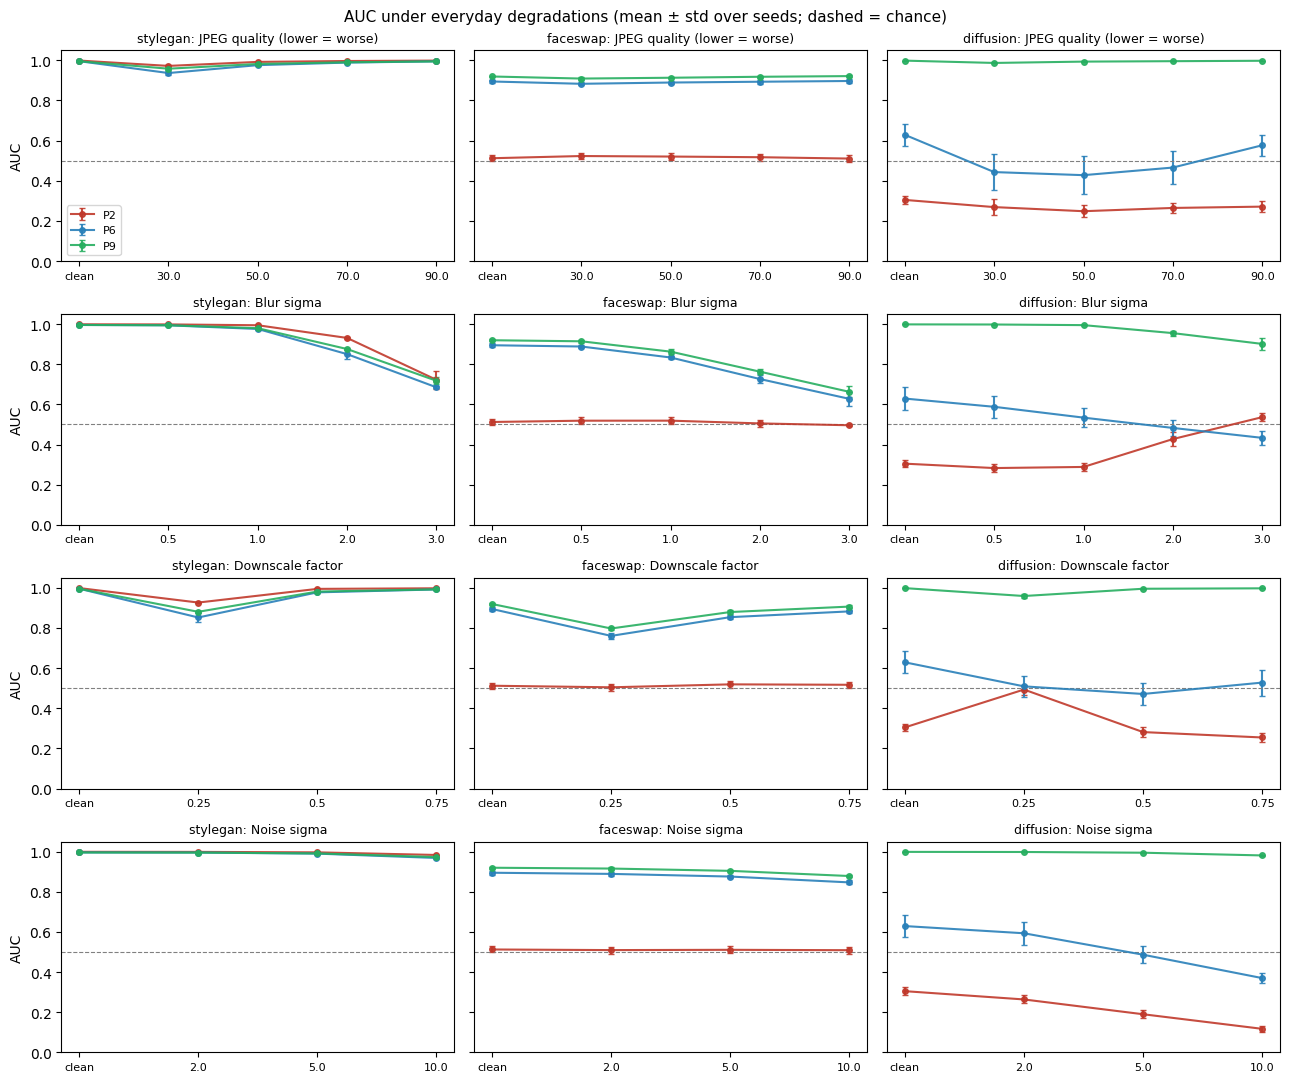

In [ ]:
import matplotlib.pyplot as plt
fams = [("jpeg", "JPEG quality (lower = worse)"), ("blur", "Blur sigma"), ("down", "Downscale factor"), ("noise", "Noise sigma")]
cols = {"p2": "#c0392b", "p6": "#2980b9", "p9": "#27ae60"}
fig, axes = plt.subplots(len(fams), 3, figsize=(13, 11), sharey=True)
for i, (fam, title) in enumerate(fams):
    for j, d in enumerate(EVAL_SETS):
        ax = axes[i, j]
        for m in ["p2", "p6", "p9"]:
            g = agg[(agg.model == m) & (agg.domain == d) & (agg.family == fam)].sort_values("level")
            c0 = agg[(agg.model == m) & (agg.domain == d) & (agg.condition == "clean")]
            if g.empty: continue
            order = list(g.level); labels = ["clean"] + [str(l) for l in order]
            y = [c0.auc_mean.iloc[0]] + list(g.auc_mean); e = [c0.auc_std.iloc[0]] + list(g.auc_std)
            ax.errorbar(range(len(y)), y, yerr=np.nan_to_num(e), marker="o", ms=4, capsize=2, color=cols[m], label=m.upper(), alpha=.9)
        ax.axhline(.5, ls="--", c="gray", lw=.8); ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8); ax.set_ylim(0, 1.05)
        ax.set_title(f"{d}: {title}", fontsize=9)
        if j == 0: ax.set_ylabel("AUC")
axes[0, 0].legend(fontsize=8, loc="lower left")
plt.suptitle("AUC under everyday degradations (mean ± std over seeds; dashed = chance)", fontsize=11)
plt.tight_layout(); plt.savefig(f"{DEG_DIR}/degradation_curves.png", dpi=200); plt.show()

In [ ]:
# Paired bootstrap (seed 0): is the AUC change vs clean larger than test-set noise? Meaningful pairs only.
from scipy.stats import rankdata
def auc_fast(pos, neg):
    n1, n0 = len(pos), len(neg); r = rankdata(np.concatenate([pos, neg]))
    return (r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def change_ci(r, p0, p1, n_boot=N_BOOT, seed=0):
    rng = np.random.default_rng(seed); ip, ineg = np.where(r)[0], np.where(~r)[0]; out = np.empty(n_boot)
    for b in range(n_boot):
        bp, bn = rng.choice(ip, len(ip)), rng.choice(ineg, len(ineg)); out[b] = auc_fast(p1[bp], p1[bn]) - auc_fast(p0[bp], p0[bn])
    return out.mean(), *np.percentile(out, [2.5, 97.5])
rows = []
for (m, d) in meaning:
    tag = f"{m}_seed0"
    if tag not in MODELS: continue
    r, p0 = RES[("clean", d)][tag]
    for cname in CONDS:
        if cname == "clean": continue
        r2, p1 = RES[(cname, d)][tag]; assert np.array_equal(r, r2)
        mu, lo, hi = change_ci(r, p0, p1)
        rows.append({"model": m, "domain": d, "condition": cname, "auc_clean": roc_auc_score(r, p0), "auc_degraded": roc_auc_score(r, p1),
                     "change": mu, "ci_lo": lo, "ci_hi": hi})
BT = pd.DataFrame(rows); BT.to_csv(f"{DEG_DIR}/degradation_bootstrap_seed0.csv", index=False)
print("=== Paired bootstrap on AUC change vs clean (seed 0, meaningful pairs) ===")
print(BT.round(4).to_string(index=False))
print("\nSaved everything to", DEG_DIR)

=== Paired bootstrap on AUC change vs clean (seed 0, meaningful pairs) ===
model    domain    condition  auc_clean  auc_degraded  change   ci_lo   ci_hi
   p9 diffusion      jpeg_90     0.9984        0.9977 -0.0008 -0.0012 -0.0004
   p9 diffusion      jpeg_70     0.9984        0.9957 -0.0028 -0.0042 -0.0015
   p9 diffusion      jpeg_50     0.9984        0.9937 -0.0048 -0.0073 -0.0027
   p9 diffusion      jpeg_30     0.9984        0.9864 -0.0121 -0.0163 -0.0082
   p9 diffusion     blur_0.5     0.9984        0.9978 -0.0006 -0.0011 -0.0002
   p9 diffusion       blur_1     0.9984        0.9940 -0.0045 -0.0070 -0.0023
   p9 diffusion       blur_2     0.9984        0.9417 -0.0567 -0.0681 -0.0453
   p9 diffusion       blur_3     0.9984        0.8763 -0.1219 -0.1408 -0.1056
   p9 diffusion    down_0.75     0.9984        0.9976 -0.0009 -0.0016 -0.0003
   p9 diffusion     down_0.5     0.9984        0.9950 -0.0035 -0.0054 -0.0017
   p9 diffusion    down_0.25     0.9984        0.9480 -0.0505 -0.06

## How to read the results (before sending them to me)

1. **Start with the robustness summary.** For each meaningful pair, how far is the worst AUC from the clean AUC, and which degradation causes it?
2. **Look at the curves.** A gentle slope is robust; a cliff means one degradation breaks the detector (JPEG and downscaling are the usual culprits because they erase the fine traces detectors rely on).
3. **Compare models.** Does training on mixed sources (P6, P9) also make a model more robust, or only more general? The curves show both.
4. **Compare domains.** Is the damage the same on StyleGAN, face-swap and diffusion, or does one domain collapse sooner?
5. **Link it to notebook 13.** If a degradation like JPEG or downscaling hurts diffusion much more than the other domains, that fits the idea that diffusion detection leaned on format or resolution cues.

**Honest limits to write in the thesis**
- These are synthetic degradations, not images actually downloaded from social platforms.
- Only ResNet18-based models were tested; the models were not trained with any degradation (no augmentation), so poor results are expected and are a finding, not a bug.
- A natural follow-up is retraining with random JPEG/blur/downscale augmentation.

**Please send back** the executed notebook.